# **load import**

In [2]:
pip --version



pip 26.2.2 from C:\Users\KIIT\AppData\Local\Programs\Python\Python314\Lib\site-packages\pip (python 3.14)

Note: you may need to restart the kernel to use updated packages.


In [6]:
import tensorflow as tf
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt
import numpy as np
import os

print("TensorFlow:", tf.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("NumPy:", np.__version__)
print("OS imported successfully!")

TensorFlow: 2.22.0-rc0
Matplotlib: 3.11.2
NumPy: 2.5.4
OS imported successfully!


# Set all the Constants (hyper parameters)
are hyperparameters that define key aspects of how the training process will be conducted.

1 BATCH_SIZE:

It represents the number of training examples utilized in one iteration. In simple terms, during each iteration of training, the
model updates its weights based on a subset of the entire dataset. The choice of batch size can affect training speed and
memory requirements.

2 IMAGE_SIZE:

This typically refers to the dimensions (width and height) of the input images. The neural network architecture and the training
process often depend on the size of the input images. It's essential to ensure consistency in image size to feed into the
network.

3 CHANNEL:

It represents the number of color channels in the input images. For example, RGB images have three channels (Red, Green,
Blue). Grayscale images have one channel. The number of channels influences the

In [7]:
BATCH_SIZE = 32
IMAGE_SIZE = 255
CHANNEL = 3
EPOCHS = 20

In [58]:
dataset = tf.keras.preprocessing.image_dataset_from_directory(
directory="PlantVillage",
seed = 123,
shuffle=True,
image_size=[IMAGE_SIZE,IMAGE_SIZE],
batch_size=BATCH_SIZE,
)

Found 1500 files belonging to 3 classes.


In [59]:
len(dataset)


47

In [60]:
class_names=dataset.class_names

In [61]:
for batch_size , label_size in dataset.take(1):
    print("Image Shape:",batch_size.shape)
    print("label:",label_size.numpy)
    print("image",batch_size[0]) #pixel value

Image Shape: (32, 255, 255, 3)
label: <bound method _EagerTensorBase.numpy of <tf.Tensor: shape=(32,), dtype=int32, numpy=
array([0, 0, 1, 2, 0, 2, 1, 2, 0, 0, 1, 1, 2, 2, 0, 2, 2, 0, 1, 0, 0, 2,
       2, 2, 2, 1, 2, 0, 2, 0, 0, 0], dtype=int32)>>
image tf.Tensor(
[[[167.02745  169.02745  182.02745 ]
  [176.00192  178.00192  191.00192 ]
  [175.88828  177.88828  190.88828 ]
  ...
  [176.95114  178.95114  190.95114 ]
  [190.92     192.92     204.92    ]
  [194.95892  196.95892  208.95892 ]]

 [[172.05095  174.05095  187.05095 ]
  [176.99992  178.99992  191.99992 ]
  [173.91788  175.91788  188.91788 ]
  ...
  [201.93027  203.93027  215.93027 ]
  [192.05283  194.05283  206.05283 ]
  [178.09192  180.09192  192.09192 ]]

 [[178.9627   180.9627   193.9627  ]
  [179.91187  181.91187  194.91187 ]
  [174.91185  176.91185  189.91185 ]
  ...
  [199.99042  201.99042  213.99042 ]
  [191.07185  193.07185  205.07185 ]
  [189.13115  191.13115  203.13115 ]]

 ...

 [[109.99605  106.99605  117.99605 ]
 

# **VISUALIZE SOME OF THE IMAGES FROM OUR DATASET**

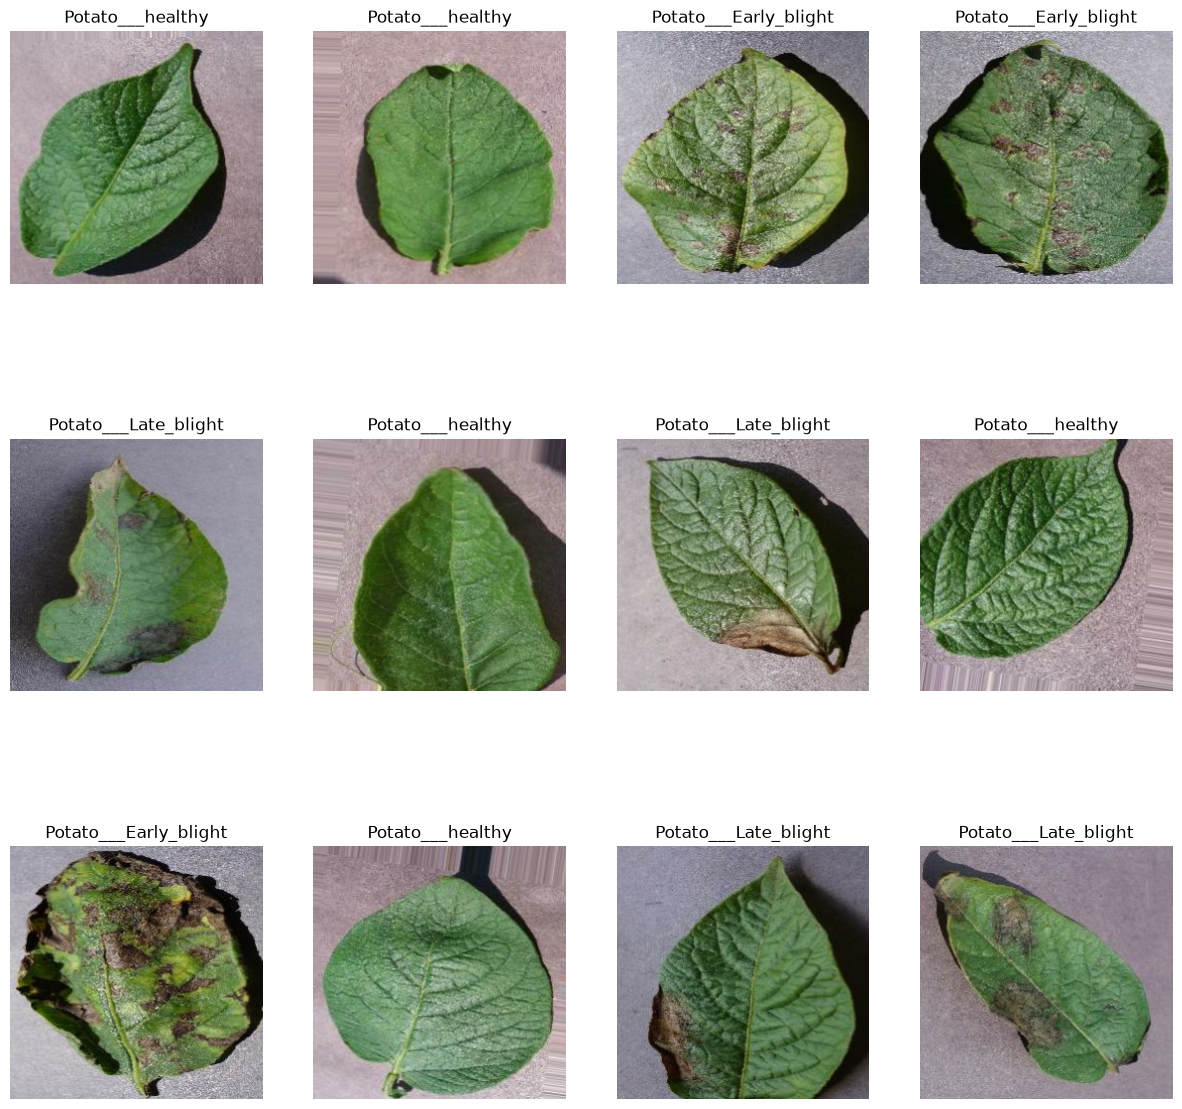

In [62]:
plt.figure(figsize=(15,15))
for img , label in dataset.take(1):
    for i in range(12):
        ax = plt.subplot(3,4,i+1)
        plt.imshow(img[i].numpy().astype("uint8"))
        plt.title(class_names[label[i]])
        plt.axis('off')

# Function to Split Dataset
Dataset should be bifurcated into 3 subsets, namely:

Training: Dataset to be used while training

Validation: Dataset to be tested against while training

Test: Dataset to be tested against after we trained a model

In [63]:
train_size = 0.8
len(dataset) * train_size

37.6

In [64]:
train_ds = dataset.take(37)

In [65]:
test_ds = dataset.skip(37)

In [66]:
len(test_ds)

10

In [67]:
val_size=0.1
len(dataset) * val_size

4.7

In [68]:
val_ds = test_ds.take(5)

In [69]:
len(val_ds)

5

In [70]:
test_ds = test_ds.skip(5)

In [71]:
len(val_ds)

5

In [72]:

import math

def get_dataset_partitions_tf(
    ds,
    train_split=0.8,
    val_split=0.1,
    test_split=0.1,
    shuffle=True,
    shuffle_size=10000
):
    assert math.isclose(train_split + val_split + test_split, 1.0), \
        "Train, validation, and test splits must sum to 1."

    ds_size = len(ds)

    if shuffle:
        ds = ds.shuffle(shuffle_size, seed=12)

    train_size = int(train_split * ds_size)
    val_size = int(val_split * ds_size)

    train_ds = ds.take(train_size)
    val_ds = ds.skip(train_size).take(val_size)
    test_ds = ds.skip(train_size + val_size)

    return train_ds, val_ds, test_ds


train_ds, val_ds, test_ds = get_dataset_partitions_tf(dataset)


     

In [73]:
len(train_ds),len(val_ds),len(test_ds)

(37, 4, 6)

# **Cache, Shuffle, and Prefetch the Dataset**
additional transformations is commonly used in TensorFlow to optimize the performance of the input pipeline when training machine learning models

1 Cache: This method caches elements from the dataset in memory. Caching is useful to speed up the training process, especially when dealing with large
datasets.

2 Shuffle: This method shuffles the elements of the dataset. The argument 1000 represents the size of the buffer used for shuffling. In other words, it randomly

samples 1000 elements from the dataset and then picks one of them to be the next element in the shuffled dataset

3 Prefetch: This method prefetches elements from the dataset to improve training performance. The buffer_size parameter determines the number of elements
to prefetch. tf.data.AUTOTUNE is used to automatically tune the prefetch buffer size based on available system resources.

In [74]:
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds = test_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)

# **Building the Model**
Creating a Layer for Resizing and Normalization Before we feed our images to network, we should be resizing it to the desired size. Moreover, to improve
model performance, we should normalize the image pixel value (keeping them in range 0 and 1 by dividing by 256). This should happen while training as well
as inference. Hence we can add that as a layer in our Sequential Model.

You might be thinking why do we need to resize (256,256) image to again (256,256). You are right we don't need to but this will be useful when we are done
with the training and start using the model for predictions. At that time somone can supply an image that is not (256,256) and this layer will resize it

In [75]:
resize_and_rescale = tf.keras.Sequential([
    layers.Resizing(IMAGE_SIZE, IMAGE_SIZE),
    layers.Rescaling(1./255)
])


# **Data Augmentation**

Data Augmentation is needed when we have less data, this boosts the accuracy of our model by augmenting the data

In [76]:
data_augmentation = tf.keras.Sequential([
layers.RandomFlip('horizontal_and_vertical'),
layers.RandomRotation(0.2)
])

# **Applying Data Augmentation to Train Dataset**

map(lambda x, y: (data_augmentation(x, training=True), y)): This line applies a mapping function to each element in the dataset. The mapping function is a
lambda function that takes two arguments x and y, which are typically an input feature and its corresponding label. It applies a data augmentation function
(data_augmentation) to the input feature x when training=True. Data augmentation is a technique used to artificially increase the diversity of the training
dataset by applying random transformations to the input data, which helps improve the model's generalization.

In [77]:
train_ds = train_ds.map(lambda x,y: (data_augmentation(x, training=True),y)).prefetch(buffer_size=tf.data.AUTOTUNE)

In [78]:
train_ds

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 255, 255, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>

# **Model Architecture**

We use a CNN coupled with a Softmax activation in the output layer. We also add the initial layers for resizing, normalization and Data Augmentation.

In [79]:
input_shape = (BATCH_SIZE, IMAGE_SIZE, IMAGE_SIZE, CHANNEL)
n_classes = 3

model = models. Sequential([
    resize_and_rescale,
    layers.Conv2D(32, kernel_size = (3,3), activation='relu', input_shape=input_shape),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, kernel_size = (3,3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, kernel_size = (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(n_classes, activation='softmax')
])
model.build(input_shape=input_shape)
model.summary()
    


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┓
┃ Layer (type)             ┃ Output Shape      ┃   Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━┩
│ sequential_6             │ (32, 255, 255, 3) │         0 │
│ (Sequential)             │                   │           │
├──────────────────────────┼───────────────────┼───────────┤
│ conv2d_24 (Conv2D)       │ (32, 253, 253,    │       896 │
│                          │ 32)               │           │
├──────────────────────────┼───────────────────┼───────────┤
│ max_pooling2d_24         │ (32, 126, 126,    │         0 │
│ (MaxPooling2D)           │ 32)               │           │
├──────────────────────────┼───────────────────┼───────────┤
│ conv2d_25 (Conv2D)       │ (32, 124, 124,    │    18,496 │
│                          │ 64)               │           │
├──────────────────────────┼───────────────────┼───────────┤
│ max_pooling2d_25         │ (32, 62, 62, 64)  │         0 │
│ (MaxPooling2D)           │                   │           │
├──────────────────────────┼───────────────────┼───────────┤
│ conv2d_26 (Conv2D)       │ (32, 60, 60, 64)  │    36,928 │
├──────────────────────────┼───────────────────┼───────────┤
│ max_pooling2d_26         │ (32, 30, 30, 64)  │         0 │
│ (MaxPooling2D)           │                   │           │
├──────────────────────────┼───────────────────┼───────────┤
│ conv2d_27 (Conv2D)       │ (32, 28, 28, 64)  │    36,928 │
├──────────────────────────┼───────────────────┼───────────┤
│ max_pooling2d_27         │ (32, 14, 14, 64)  │         0 │
│ (MaxPooling2D)           │                   │           │
├──────────────────────────┼───────────────────┼───────────┤
│ conv2d_28 (Conv2D)       │ (32, 12, 12, 64)  │    36,928 │
├──────────────────────────┼───────────────────┼───────────┤
│ max_pooling2d_28         │ (32, 6, 6, 64)    │         0 │
│ (MaxPooling2D)           │                   │           │
├──────────────────────────┼───────────────────┼───────────┤
│ conv2d_29 (Conv2D)       │ (32, 4, 4, 64)    │    36,928 │
├──────────────────────────┼───────────────────┼───────────┤
│ max_pooling2d_29         │ (32, 2, 2, 64)    │         0 │
│ (MaxPooling2D)           │                   │           │
├──────────────────────────┼───────────────────┼───────────┤
│ flatten_4 (Flatten)      │ (32, 256)         │         0 │
├──────────────────────────┼───────────────────┼───────────┤
│ dense_8 (Dense)          │ (32, 64)          │    16,448 │
├──────────────────────────┼───────────────────┼───────────┤
│ dense_9 (Dense)          │ (32, 3)           │       195 │
└──────────────────────────┴───────────────────┴───────────┘

 Total params: 183,747 (717.76 KB)

 Trainable params: 183,747 (717.76 KB)

 Non-trainable params: 0 (0.00 B)

# **Compiling the Model**

We use adam Optimizer, SparseCategoricalCrossentropy for losses, accuracy as a metric

In [87]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("Model compiled successfully!")
model.summary()

Model compiled successfully!


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┓
┃ Layer (type)             ┃ Output Shape      ┃   Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━┩
│ sequential_6             │ (32, 255, 255, 3) │         0 │
│ (Sequential)             │                   │           │
├──────────────────────────┼───────────────────┼───────────┤
│ conv2d_24 (Conv2D)       │ (32, 253, 253,    │       896 │
│                          │ 32)               │           │
├──────────────────────────┼───────────────────┼───────────┤
│ max_pooling2d_24         │ (32, 126, 126,    │         0 │
│ (MaxPooling2D)           │ 32)               │           │
├──────────────────────────┼───────────────────┼───────────┤
│ conv2d_25 (Conv2D)       │ (32, 124, 124,    │    18,496 │
│                          │ 64)               │           │
├──────────────────────────┼───────────────────┼───────────┤
│ max_pooling2d_25         │ (32, 62, 62, 64)  │         0 │
│ (MaxPooling2D)           │                   │           │
├──────────────────────────┼───────────────────┼───────────┤
│ conv2d_26 (Conv2D)       │ (32, 60, 60, 64)  │    36,928 │
├──────────────────────────┼───────────────────┼───────────┤
│ max_pooling2d_26         │ (32, 30, 30, 64)  │         0 │
│ (MaxPooling2D)           │                   │           │
├──────────────────────────┼───────────────────┼───────────┤
│ conv2d_27 (Conv2D)       │ (32, 28, 28, 64)  │    36,928 │
├──────────────────────────┼───────────────────┼───────────┤
│ max_pooling2d_27         │ (32, 14, 14, 64)  │         0 │
│ (MaxPooling2D)           │                   │           │
├──────────────────────────┼───────────────────┼───────────┤
│ conv2d_28 (Conv2D)       │ (32, 12, 12, 64)  │    36,928 │
├──────────────────────────┼───────────────────┼───────────┤
│ max_pooling2d_28         │ (32, 6, 6, 64)    │         0 │
│ (MaxPooling2D)           │                   │           │
├──────────────────────────┼───────────────────┼───────────┤
│ conv2d_29 (Conv2D)       │ (32, 4, 4, 64)    │    36,928 │
├──────────────────────────┼───────────────────┼───────────┤
│ max_pooling2d_29         │ (32, 2, 2, 64)    │         0 │
│ (MaxPooling2D)           │                   │           │
├──────────────────────────┼───────────────────┼───────────┤
│ flatten_4 (Flatten)      │ (32, 256)         │         0 │
├──────────────────────────┼───────────────────┼───────────┤
│ dense_8 (Dense)          │ (32, 64)          │    16,448 │
├──────────────────────────┼───────────────────┼───────────┤
│ dense_9 (Dense)          │ (32, 3)           │       195 │
└──────────────────────────┴───────────────────┴───────────┘

 Total params: 183,747 (717.76 KB)

 Trainable params: 183,747 (717.76 KB)

 Non-trainable params: 0 (0.00 B)

In [88]:
history = model.fit(
    train_ds,
    batch_size=BATCH_SIZE,
    validation_data=val_ds,
    verbose=1,
    epochs=20,
)

Epoch 1/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 22s 550ms/step - accuracy: 0.4517 - loss: 1.0145 - val_accuracy: 0.6641 - val_loss: 0.7199
Epoch 2/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 18s 488ms/step - accuracy: 0.7178 - loss: 0.5893 - val_accuracy: 0.8047 - val_loss: 0.5230
Epoch 3/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 18s 484ms/step - accuracy: 0.8161 - loss: 0.4322 - val_accuracy: 0.8828 - val_loss: 0.3151
Epoch 4/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 18s 479ms/step - accuracy: 0.8873 - loss: 0.2924 - val_accuracy: 0.9531 - val_loss: 0.1517
Epoch 5/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 18s 487ms/step - accuracy: 0.9076 - loss: 0.2397 - val_accuracy: 0.9531 - val_loss: 0.2000
Epoch 6/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 18s 482ms/step - accuracy: 0.9042 - loss: 0.2643 - val_accuracy: 0.9375 - val_loss: 0.1350
Epoch 7/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 18s 489ms/step - accuracy: 0.9331 - loss: 0.1760 - val_accuracy: 0.9609 - val_loss: 0.1452
Epoch 8/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 18s 487ms/step - accuracy: 0.8966 - loss: 0.2831 - val_accu

In [90]:
all_actual = []
all_predicted = []

for images, labels in val_ds:
    predictions = model.predict(images, verbose=0)

    all_actual.extend(labels.numpy())
    all_predicted.extend(np.argmax(predictions, axis=1))

all_actual = np.array(all_actual)
all_predicted = np.array(all_predicted)

print("Actual class counts:", np.bincount(all_actual, minlength=3))
print("Predicted class counts:", np.bincount(all_predicted, minlength=3))
print("Overall validation accuracy:",
      np.mean(all_actual == all_predicted))

Actual class counts: [45 33 50]
Predicted class counts: [45 33 50]
Overall validation accuracy: 1.0


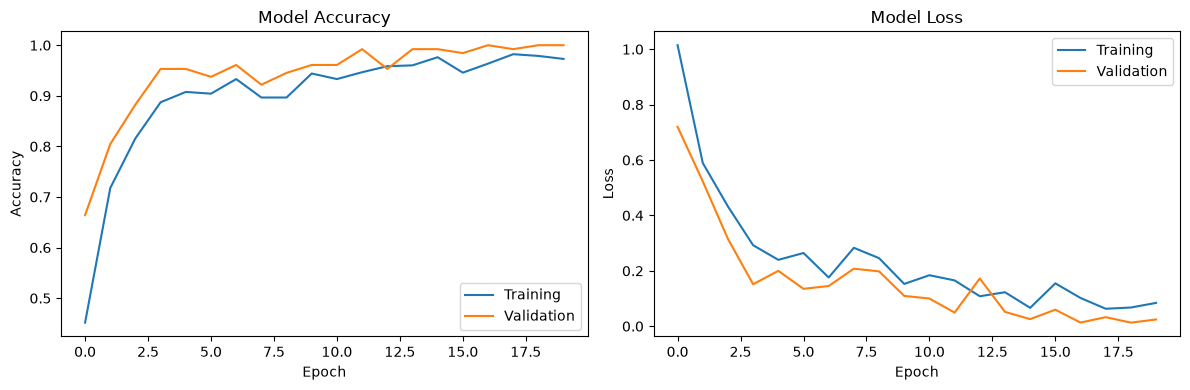

In [89]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [95]:
#model.save('model.h5')


In [97]:
model = tf.keras.models.load_model("model.h5")

model.compile(
    optimizer="adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("Model loaded and compiled successfully!")


Model loaded and compiled successfully!


In [98]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 121ms/step - accuracy: 0.9896 - loss: 0.0327
Test Accuracy: 98.96%
Test Loss: 0.0327


# **Run prediction on a sample image**

In [96]:
model = tf.keras.models. load_model('model.h5')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step
Actual Label : Potato___Early_blight
Predicted label : Potato___Early_blight


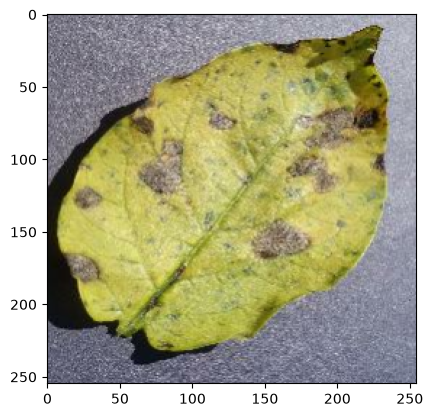

In [105]:
for img, label in test_ds.take(1):
    first_img = img[0].numpy().astype('uint8')
    first_label = label[0].numpy()
    pred_img = model.predict(img)
    plt.imshow(first_img)
    print("Actual Label :", class_names[first_label])
    print("Predicted label :",class_names[np.argmax(pred_img[0])])

# **Write a function for prediction on more images**

In [118]:
def predict(model, img):
    img_array = tf.keras.preprocessing.image.img_to_array(images[i].numpy())
    img_array = tf.expand_dims(img_array, 0)
    predictions = model.predict(img_array)
    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = round(100 * (np.max(predictions[0])), 2)
    return predicted_class, confidence

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


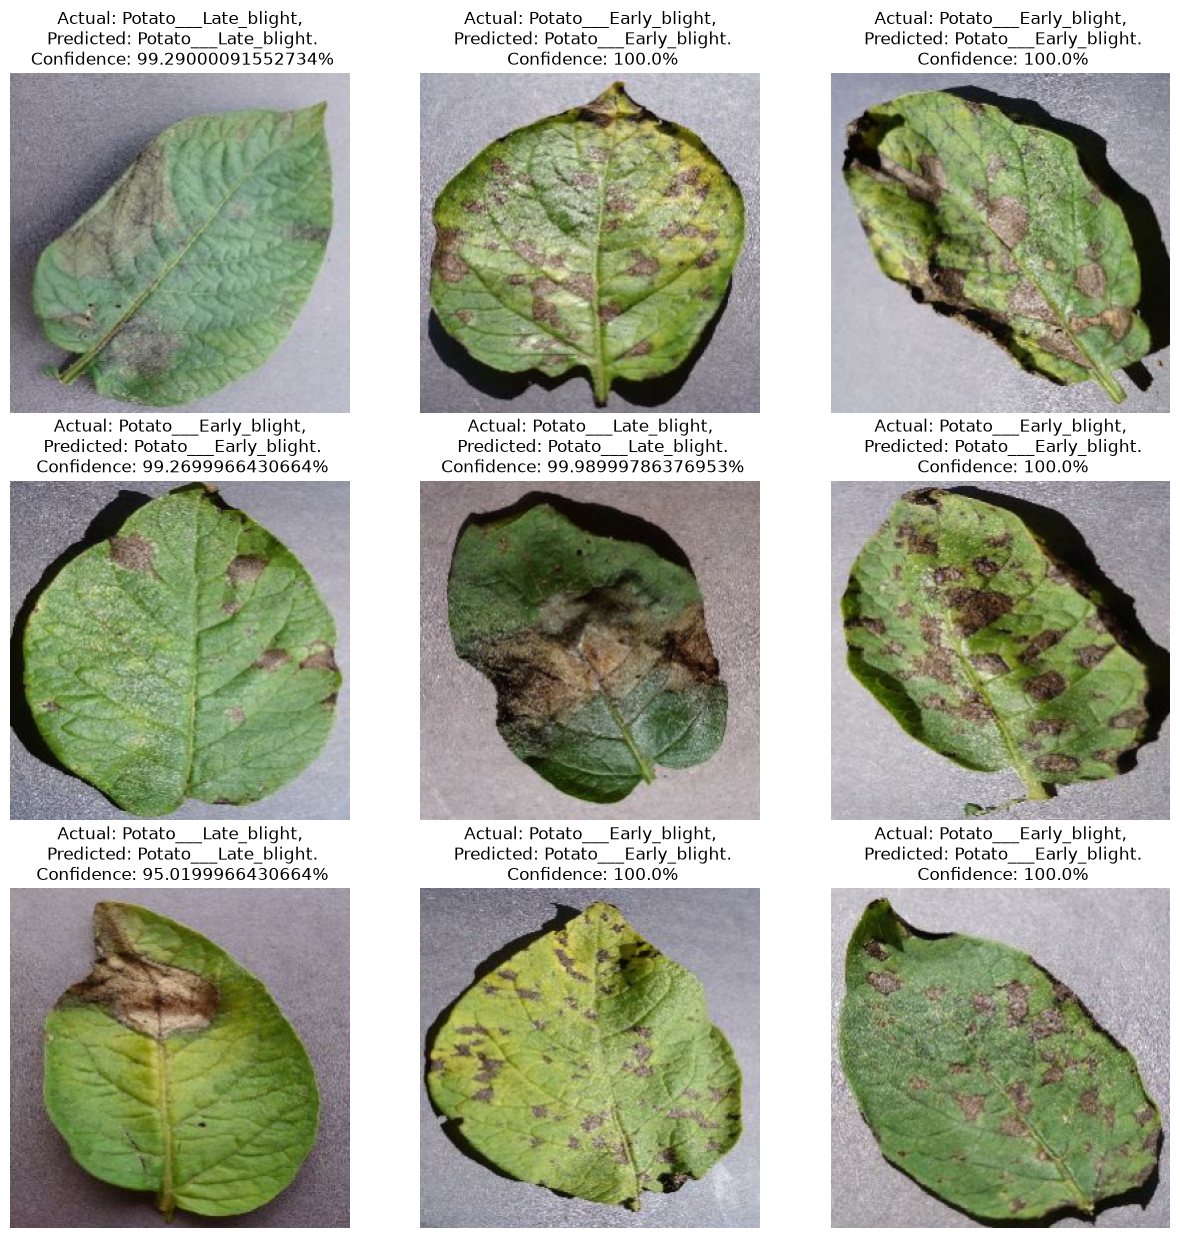

In [119]:
plt.figure(figsize=(15, 15))
for images, labels in test_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i +1)
        plt.imshow(images[i].numpy().astype("uint8"))
        predicted_class, confidence = predict(model, images[i].numpy())
        actual_class = class_names[labels [i]]
        plt.title(f"Actual: {actual_class},\n Predicted: {predicted_class}.\n Confidence: {confidence}%")
        plt.axis("off")